# 12 - Bring Your Own Controller / Plant / Topology

This notebook is a **template for other engineers**, not a paper result: it shows how to plug a
*different* controller, or an *entirely different plant*, into the exact same CRI supervisor,
safe-probing mechanism, and metrics used throughout this study. That is the point of releasing
this as a package rather than a one-off script -- the CRI framework should be usable as a
standard readiness-supervision layer for *your* controller, optimizer, RL agent, or grid model,
not only the OFO coordinator studied in the paper.

There are two levels of reuse:

| You want to... | Use | What you provide |
|---|---|---|
| Test a *new candidate controller* (your optimizer/RL/MPC/PSO tuner) on the reference microgrid | `sim.run_closed_loop(..., candidate=your_controller)` | An object satisfying `CandidateControllerProtocol` |
| Test the CRI framework on an *entirely different plant* | `sim.run_closed_loop_generic(...)` | Objects satisfying `PlantProtocol`, `CandidateControllerProtocol`, `FallbackControllerProtocol`, plus a margin function |

Both are demonstrated below. The required methods are documented as `typing.Protocol`s in
`cri_microgrid/interfaces.py` -- read that file first; this notebook is the worked example.

## The CRI Equations at a Glance

Every equation below is implemented as its own small, pure function in `cri_microgrid`, so it can
be checked line-by-line against the manuscript. Equation numbers refer to the current version of
the paper (`CRI_Main_Paper.tex`).

| Eq. | Name | Formula | Implementation |
|---|---|---|---|
| (10) | Normalized increments | $\Delta\widetilde u_k=D_u^{-1}\Delta u_k,\ \Delta\widetilde y_k=D_y^{-1}\Delta y_k$ | `config.DEFAULT_D_u`, `DEFAULT_D_y` |
| (13) | Safe-probing amplitude | $\bar\delta_k=\bar\delta_{\max}\,\mathrm{SMI}_k$ | `probing.scale_probe_with_smi` |
| (15) | Weighted regularized sensitivity | $\hat S_k=\Delta\widetilde Y_kW_k\Delta\widetilde U_k^T\left(\Delta\widetilde U_kW_k\Delta\widetilde U_k^T+\lambda_sI\right)^{-1}$ | `sensitivity.estimate_sensitivity` |
| (18)-(19) | Responsiveness | $\rho_k=\tfrac{1}{n_u}\lVert\hat S_k\rVert_F^2,\quad \mathrm{RI}_k=1-e^{-\rho_k/r_0}$ | `sensitivity.SensitivityResult.rho`, `cri.compute_RI` |
| (20)-(21) | Coupling | $c_k$ (column-normalized off-diagonal ratio), $\mathrm{CI}_k=1-c_k$ | `sensitivity.coupling_raw`, `cri.compute_CI` |
| (22)-(23) | Safety margin | $\psi_{\ell,k}=\dfrac{-g_\ell(q_k)}{m_\ell^{\mathrm{safe}}+\varepsilon_0}$, $\ \mathrm{SMI}_k=\min_\ell\mathrm{sat}_{[0,1]}(\psi_{\ell,k})$ | your `margin_fn`, `cri.compute_SMI` |
| (26) | Adaptability | $\mathrm{AI}_k=\exp(-a_k/a_0)$ | `cri.compute_AI` |
| (27) | Noise confidence | $\mathrm{NCI}_k=\exp(-\hat\sigma_{y,k}^2/\sigma_{y,0}^2)\exp(-\varepsilon_{s,k}^2/\varepsilon_{0,s}^2)$ | `cri.compute_NCI` |
| (30) | CRI combination | $\widehat{\mathrm{CRI}}_k=\omega^T\Gamma_k$, $\ \Gamma_k=[\mathrm{RI},\mathrm{CI},\mathrm{SMI},\mathrm{AI},\mathrm{NCI}]_k$ | `cri.compute_instantaneous_cri` |
| (31)-(32) | Dynamic filter | $\mathrm{CRI}_k=(1-\beta_k)\mathrm{CRI}_{k-1}+\beta_k\widehat{\mathrm{CRI}}_k$ | `cri.update_dynamic_cri`, `cri.compute_beta` |
| (33) | Classification | Activate / Monitor / Delay / Reject via $\eta_A,\eta_M,\eta_D$ | `cri.classify_readiness` |
| (35)-(36) | Activation & adaptation scaling | $s_k$, $\ \kappa_k=\mathrm{sat}_{[\kappa_{\min},1]}\!\left(\dfrac{\mathrm{CRI}_k-\eta_D}{\eta_A-\eta_D}\right)$ | `cri.compute_activation`, `cri.compute_kappa` |
| (37)-(38) | Scaled updates | shadow parameter update, blended plant command | your `shadow_update`, `controllers.blend_command` |
| (39) | Digital-twin escalation | $d_k^{\mathrm{DT}}$ | `cri.compute_dt_flag` |

Every symbol above is dimensionless and plant-agnostic: $n_u$, $n_y$, $D_u$, $D_y$, and the
constraint set are the only things that change when the framework is pointed at a new system, and
all four are supplied as ordinary arguments (`n_u`, `n_y`, `D_u`, `D_y`, `margin_fn`) rather than
hardcoded anywhere in `cri.py` or `sensitivity.py`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import matplotlib.pyplot as plt

from cri_microgrid.config import (PlantParams, ControllerParams, ConstraintParams, CRIParams,
                                   ProbeParams, ProfileParams, SimulationParams)
from cri_microgrid import scenarios, sim, plotstyle
from cri_microgrid.interfaces import check_interfaces, CandidateControllerProtocol, FallbackControllerProtocol, PlantProtocol

plotstyle.apply_style()

## Part A - Bring your own candidate controller (reference microgrid, your optimizer)

The reference plant/fallback stay exactly as used throughout the paper; only the candidate
controller changes. Any object with `candidate_command()`, `propose_nominal_step(y)`,
`shadow_update(delta, kappa)`, and `reset()` works -- below is a deliberately simple
"proportional setpoint search" controller standing in for your own optimizer, to show the
integration clearly without a real optimizer's complexity getting in the way.

In [2]:
class MyProportionalController:
    """A minimal stand-in for "your own controller": moves each VSC
    setpoint proportionally to the AC/DC voltage error, with no
    cross-VSC coordination at all (deliberately simpler than the paper's
    OFO coordinator, so its behavior under CRI supervision is easy to
    reason about)."""

    def __init__(self, gain=0.4, u0=None):
        self.gain = gain
        self.u = np.array([0.3, 0.0, 0.3, 0.0]) if u0 is None else np.asarray(u0, dtype=float)

    def candidate_command(self):
        return self.u.copy()

    def propose_nominal_step(self, y_meas):
        V1, V2, Vdc = y_meas[0], y_meas[1], y_meas[2]
        dP = self.gain * (Vdc - 1.0)
        dQ1 = self.gain * (1.0 - V1)
        dQ2 = self.gain * (1.0 - V2)
        return np.clip(np.array([-dP, dQ1, -dP, dQ2]), -0.08, 0.08)

    def shadow_update(self, delta_nominal, kappa_k):
        self.u = np.clip(self.u + kappa_k * delta_nominal, [-0.4, -0.6, -0.4, -0.6], [1.0, 0.6, 1.0, 0.6])

    def reset(self, u0=None):
        self.u = np.array([0.3, 0.0, 0.3, 0.0]) if u0 is None else np.asarray(u0, dtype=float)


check_interfaces(candidate=MyProportionalController())

Interface check passed for: candidate


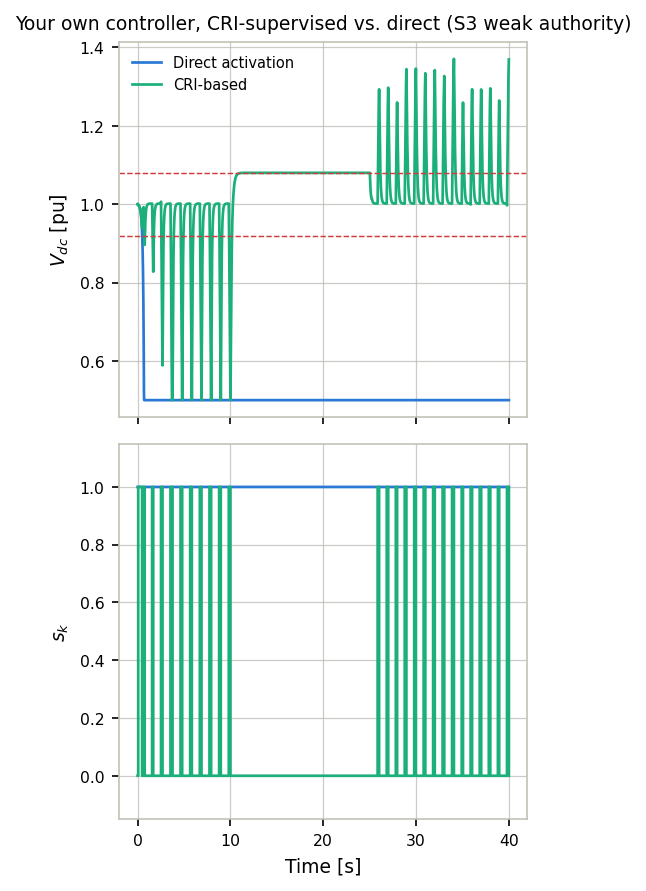

Your controller got full CRI supervision, safe probing, and every metric in metrics.py
without a single change to cri.py, sensitivity.py, or probing.py.


In [3]:
pp, cp, cons = PlantParams(), ControllerParams(), ConstraintParams()
crip, probep, prof = CRIParams(), ProbeParams(), ProfileParams()
scenario = scenarios.build_S3(pp, prof, T_end=40.0)  # the weak-authority stress scenario

logs = {}
for strategy in ["direct", "cri"]:
    simp = SimulationParams(T_end=scenario.T_end, seed=1, strategy=strategy)
    logs[strategy] = sim.run_closed_loop(scenario, pp, cp, cons, crip, probep, simp,
                                          candidate=MyProportionalController())

fig, axes = plt.subplots(2, 1, figsize=plotstyle.FIGSIZE_1COL_TALL, sharex=True)
for strategy, color in [("direct", plotstyle.STRATEGY_COLORS["direct"]), ("cri", plotstyle.STRATEGY_COLORS["cri"])]:
    axes[0].plot(logs[strategy]["t"], logs[strategy]["Vdc"], color=color, label=plotstyle.STRATEGY_LABELS[strategy])
    axes[1].step(logs[strategy]["t"], logs[strategy]["s"], where="post", color=color)
axes[0].axhline(cons.Vdc_min, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
axes[0].axhline(cons.Vdc_max, color=plotstyle.STATUS["Reject"], lw=0.7, ls="--")
axes[0].set_ylabel("$V_{dc}$ [pu]"); axes[0].legend(frameon=False, fontsize=7)
axes[0].set_title("Your own controller, CRI-supervised vs. direct (S3 weak authority)", fontsize=9)
axes[1].set_ylabel("$s_k$"); axes[1].set_xlabel("Time [s]"); axes[1].set_ylim(-0.15, 1.15)
plt.tight_layout(); plt.show()

print("Your controller got full CRI supervision, safe probing, and every metric in metrics.py")
print("without a single change to cri.py, sensitivity.py, or probing.py.")

## Part B - Bring your own plant (a completely different system)

For a genuinely different plant (not the 4-input/7-output microgrid), use
`sim.run_closed_loop_generic`. You supply the plant, both controllers, the dimensions, and a
`margin_fn` that turns your own constraint set into normalized margins (Eq. 17-18) -- everything
else (the five indicators, the CRI combination/filter/classification, safe probing) is identical
to what powers every other notebook in this repository.

The toy system below is a deliberately trivial single-input/two-output first-order plant, chosen
so the *integration pattern* is easy to see -- swap in your real plant model (a different
converter topology, a different number of buses, a mechanical system, anything with a command
vector and a measurement vector) by replacing `ToyPlant` with your own class satisfying
`PlantProtocol`.

In [4]:
class ToyPlant:
    """A minimal PlantProtocol example: one input drives one first-order
    state; the second output is a fixed linear function of it. Replace
    this entirely with your own system -- only the method signatures
    below need to match."""

    def __init__(self, tau=0.2):
        self.tau = tau
        self.x = 0.5

    def measure(self, exo, noise_cfg=None):
        y = np.array([self.x, 0.5 * self.x])
        return y, dict(x_true=self.x)  # hidden_truth: yours to define, validation-only

    def step(self, u, t, exo, actuator_gain, topo, noise_cfg=None):
        g = 1.0 if actuator_gain is None else actuator_gain
        dt = 0.05
        self.x += (dt / self.tau) * (g * u[0] - self.x)
        y = np.array([self.x, 0.5 * self.x])
        return y, dict(x_true=self.x)


class ToyFallback:
    def command(self, y_meas):
        return np.array([0.3])


class ToyCandidate:
    """A simple one-channel gradient controller driving y[0] -> 1.0."""

    def __init__(self):
        self.u = np.array([0.3])

    def candidate_command(self):
        return self.u.copy()

    def propose_nominal_step(self, y_meas):
        return np.array([0.05 * (1.0 - y_meas[0])])

    def shadow_update(self, delta_nominal, kappa_k):
        self.u = np.clip(self.u + kappa_k * delta_nominal, -1.0, 1.0)

    def reset(self, u0=None):
        self.u = np.array([0.3]) if u0 is None else np.asarray(u0, dtype=float)


def toy_margin_fn(y_meas, u_applied, cons):
    """One constraint: y[0] should stay within +-0.9 of 1.0. Returns a
    single normalized margin in ~[0,1]; SMI is the min across whatever
    list you return here (Eq. 17-18)."""
    return [1.0 - abs(y_meas[0] - 1.0) / 0.9]


check_interfaces(candidate=ToyCandidate(), fallback=ToyFallback(), plant=ToyPlant())

Interface check passed for: candidate, fallback, plant


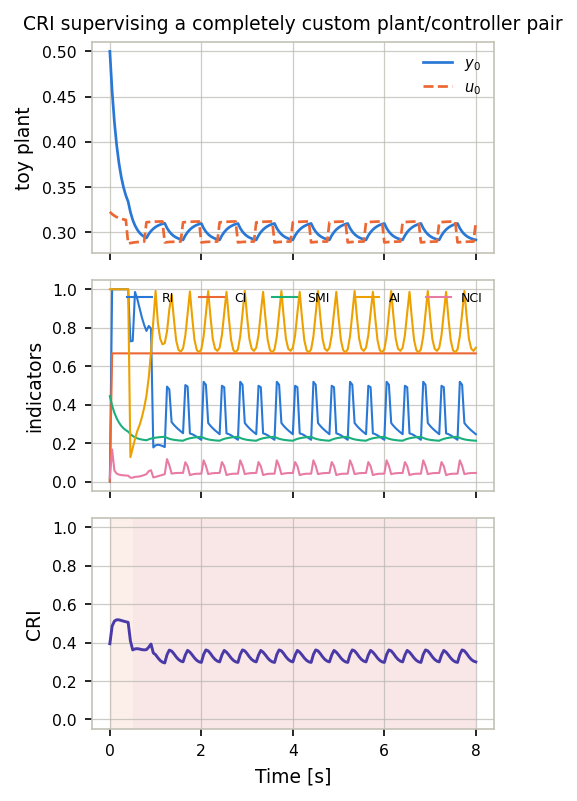

In [5]:
toy_scenario = scenarios.Scenario(
    name="toy_demo", T_end=8.0,
    exogenous_fn=lambda t: {}, actuator_gain_fn=lambda t: 1.0, topology_fn=lambda t: None,
    noise_cfg=dict(enabled=False),
)
crip_toy = CRIParams(N=10, Na=5, r0=0.02, a0=0.1)
simp_toy = SimulationParams(Ts=0.05, T_end=toy_scenario.T_end, seed=0, strategy="cri")

log_toy = sim.run_closed_loop_generic(
    toy_scenario, crip_toy, ProbeParams(), simp_toy,
    plant=ToyPlant(), fallback=ToyFallback(), candidate=ToyCandidate(),
    n_u=1, n_y=2, cons=None, margin_fn=toy_margin_fn,
    u_bounds=(np.array([-1.0]), np.array([1.0])),
)

t = log_toy["t"]
fig, axes = plt.subplots(3, 1, figsize=plotstyle.FIGSIZE_1COL_STACK3, sharex=True)
axes[0].plot(t, log_toy["y_meas"][:, 0], color=plotstyle.CAT["blue"], label="$y_0$")
axes[0].plot(t, log_toy["u_applied"][:, 0], color=plotstyle.CAT["orange"], label="$u_0$", ls="--")
axes[0].legend(frameon=False, fontsize=7); axes[0].set_ylabel("toy plant")
axes[0].set_title("CRI supervising a completely custom plant/controller pair", fontsize=9)

for name in ["RI", "CI", "SMI", "AI", "NCI"]:
    axes[1].plot(t, log_toy[name], color=plotstyle.INDICATOR_COLORS[name], lw=1.0, label=name)
axes[1].set_ylim(-0.05, 1.05); axes[1].legend(frameon=False, fontsize=6, ncol=5); axes[1].set_ylabel("indicators")

plotstyle.shade_classification_bg(axes[2], t, log_toy["cls_code"])
axes[2].plot(t, log_toy["CRI"], color=plotstyle.INDICATOR_COLORS["CRI"], lw=1.4)
axes[2].set_ylabel("CRI"); axes[2].set_xlabel("Time [s]"); axes[2].set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

## Adapting this to a real new grid/topology

To go from the toy example above to a real new grid, controller, or optimization scheme:

1. **Copy `cri_microgrid/plant.py` as a starting template**, not a constraint -- keep the
   `measure()`/`step()` method signatures, replace the physics inside with your own DAE/averaged
   model. Anything can go in `hidden_truth`; nothing in it reaches the CRI.
2. **Copy `cri_microgrid/controllers.py`'s `OFOVSCController`** as a template for wrapping your
   own optimizer/RL agent/tuner as a `CandidateControllerProtocol` -- the only real constraint is
   separating "the command implied by current state" (`candidate_command`) from "how state
   changes given new data" (`propose_nominal_step` + `shadow_update`).
3. **Write your own `margin_fn`** from your own constraint set, following the pattern in
   `cri.microgrid_margins` (Eq. 17-18): each margin should be ~1 deep inside the limit, ~0 at it.
4. **Reuse everything else as-is**: `cri.py`, `sensitivity.py`, `probing.py`, `metrics.py`, and
   `validation.py` (write your own `z_k^unsafe` ground-truth rule, same pattern as
   `validation.compute_unsafe_truth`) do not need to change at all.
5. Run the same **Direct / Threshold / CRI** three-way comparison used throughout this repository
   (`sim.run_closed_loop_generic` with `strategy="direct"/"threshold"/"cri"`) to get a fair,
   paired evaluation of whether CRI supervision helps *your* controller on *your* system.

This is the intended long-term contribution of releasing this framework as a package: a
plug-in-your-own-controller/optimizer/topology harness for evaluating control readiness beyond
the specific microgrid case study in the paper.

## Parameter Reference for a New Plant or Controller

`CRIParams` (in `cri_microgrid/config.py`) holds every tunable number the CRI engine uses. The
values below are this study's defaults; the right-hand column indicates what actually needs
re-tuning when the framework is pointed at a different plant, and what can usually be left alone.

| Parameter | Symbol | Default | Re-tune for a new system? |
|---|---|---|---|
| `N` | Window length | 40 | Yes -- scale with your sample time so the window spans a few times the plant's dominant time constant. |
| `Na` | Adaptability window | 20 | Yes -- typically `N/2`. |
| `lambda_s` | Sensitivity regularization | 1e-3 | Rarely -- only increase if `condition_number` in the logged output is persistently large. |
| `r0` | Responsiveness normalization | 0.06 | Yes -- set from the sensitivity energy $\rho_k$ your own healthy plant actually reaches (see `notebooks/09_parameter_sensitivity.ipynb` for how this was calibrated here). |
| `a0` | Adaptability normalization | 0.12 | Yes -- the maximum normalized operating-point drift per `Na`-sample block you consider acceptable. |
| `sigma_y0_sq` | Noise normalization | 3e-3 | Yes -- set from your sensor noise floor, in the same $D_y$-normalized units. |
| `epsilon_0s` | Residual normalization | 0.50 | Yes -- calibrate jointly with `sigma_y0_sq` against a known-degraded case, as documented in `config.py`. |
| `omega_R,C,S,A,N` | CRI weights | 0.20, 0.10, 0.30, 0.15, 0.25 | Optional -- must sum to 1 (enforced by an assertion in `CRIParams.__post_init__`); the defaults are safety-oriented (SMI and NCI weighted highest). |
| `eta_A, eta_M, eta_D` | Decision thresholds | 0.64, 0.565, 0.40 | Yes -- calibrate against your own plant's achievable *nominal* CRI ceiling, not against 1.0 (see the note on SMI's structural ceiling below). |
| `eta_S, eta_N` | DT-escalation thresholds | 0.30, 0.35 | Optional. |
| `beta_min, beta_max, kappa_beta` | Dynamic-filter rate | 0.05, 0.50, 2.0 | Optional -- controls how fast the CRI trusts a new instantaneous reading vs. its own history. |
| `kappa_min` | Shadow-learning floor | 0.05 | Optional. |
| `delta_max` | Max probing amplitude | 0.05 pu | Yes -- the largest safe perturbation your actuators can absorb without themselves causing a constraint excursion. |

Two general calibration notes carry over to any new plant:

- **SMI has a structural ceiling whenever it is a `min` of several headroom fractions that sum to a
  fixed budget** -- it will not reach 1.0 even at the best possible operating point. Calibrate
  `eta_A`/`eta_M`/`eta_D` against your own plant's achievable nominal CRI, the same way this study's
  thresholds were set with headroom below its own ~0.7 nominal ceiling rather than against an
  unreachable 1.0.
- **RI is a scalar aggregate.** If your plant has multiple actuators, a healthy channel can mask a
  degraded one in $\rho_k$ alone -- NCI and SMI typically catch what RI alone misses (see
  `notebooks/08_direct_vs_cri.ipynb`, scenario S3, for a worked example of this on the reference
  microgrid).

## Interface Contract Summary

The three `typing.Protocol`s in `cri_microgrid/interfaces.py` are the entire integration surface.
Nothing else in `cri_microgrid` needs to change to support a new controller or plant.

| Protocol | Required methods | Used for |
|---|---|---|
| `CandidateControllerProtocol` | `candidate_command()`, `propose_nominal_step(y_meas)`, `shadow_update(delta_nominal, kappa_k)`, `reset(u0=None)` | Your optimizer, RL policy, PSO/HHO tuner, or neural adaptive controller |
| `FallbackControllerProtocol` | `command(y_meas)` | The conservative, always-trusted controller used whenever $s_k=0$ |
| `PlantProtocol` | `measure(exo, noise_cfg=None)`, `step(u, t, exo, actuator_gain, topo, noise_cfg=None)` | Your simulated (or, for HIL, your interfaced real-time) system |

`interfaces.check_interfaces(candidate=..., fallback=..., plant=...)` validates any subset of these
before a run starts, raising a clear `AttributeError` naming exactly which method is missing,
instead of failing deep inside a simulation loop.

## From Simulation to Hardware-in-the-Loop and Experimental Validation

Everything above runs the CRI engine against a Python plant object. The same engine -- unchanged --
is designed to carry forward through progressively more realistic execution environments, so a
development team can move from a pure software study to a physical deployment without rewriting
the readiness layer at any stage. Only the object passed as `plant` (and, on real hardware, the
I/O layer that produces it) changes.

| Stage | What runs | What changes vs. this notebook | What stays identical |
|---|---|---|---|
| **1. Software-in-the-loop (SIL)** | Everything in Python, as demonstrated above | Nothing -- this is exactly Part A / Part B | -- |
| **2. Virtual HIL** | A higher-fidelity plant model (EMT/DAE solver, PLECS/Simulink co-simulation, or a switched-converter model) in place of `ToyPlant`/`HybridACDCPlant` | Only `PlantProtocol.measure()`/`step()`, which now call out to the external solver instead of integrating a closed-form model in pure Python | `cri.py`, `sensitivity.py`, `probing.py`, `metrics.py`, and every notebook's analysis code |
| **3. Real-time HIL** | The candidate/fallback controllers and the CRI supervisor ported to run within a fixed real-time step on a DSP/FPGA or industrial PC, exchanging I/O with a real-time-simulated power stage (e.g. Typhoon HIL, OPAL-RT, dSPACE, PLECS RT Box, Speedgoat) | The control-path functions are re-implemented in C/HDL (see the porting checklist below); the plant becomes a real-time target, not a Python object | The same five indicators, the same combination/filter/classification logic, and the same safe-probing law -- ported line-for-line, not redesigned |
| **4. Experimental prototype** | The ported controller driving a real (scaled or full-power) physical system | Sensors/ADC replace `noise_cfg`; actuator saturation is physical, not a `np.clip` | The log schema (see below), so `metrics.py` and every plotting routine in this repository work unchanged on hardware data |

The figure below summarizes this path; it is a guide for extending this framework beyond the
simulation study, not a record of what has been executed on physical hardware.

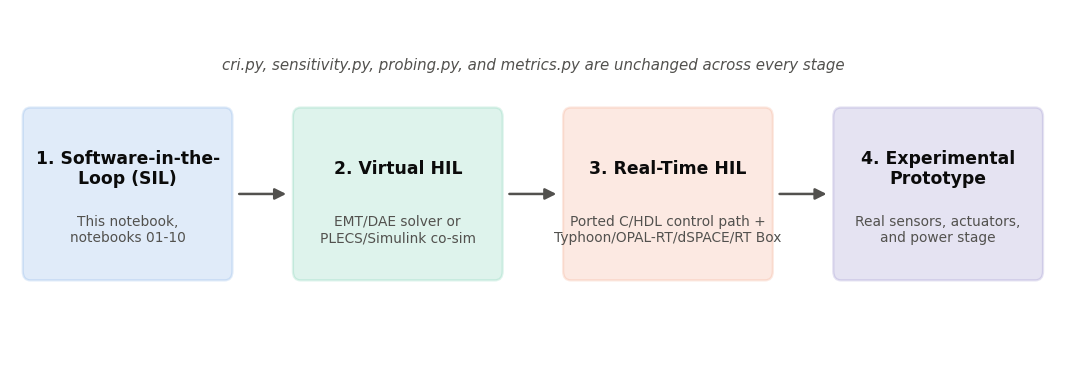

In [6]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.lines import Line2D

stages = [
    ("1. Software-in-the-\nLoop (SIL)", "This notebook,\nnotebooks 01-10", plotstyle.CAT["blue"]),
    ("2. Virtual HIL", "EMT/DAE solver or\nPLECS/Simulink co-sim", plotstyle.CAT["aqua"]),
    ("3. Real-Time HIL", "Ported C/HDL control path +\nTyphoon/OPAL-RT/dSPACE/RT Box", plotstyle.CAT["orange"]),
    ("4. Experimental\nPrototype", "Real sensors, actuators,\nand power stage", plotstyle.CAT["violet"]),
]

fig, ax = plt.subplots(figsize=(plotstyle.IEEE_PAGE_WIDTH_IN, 2.6))
box_w, box_h, gap = 1.55, 1.05, 0.55
x0, y0 = 0.1, 0.6

for i, (title, subtitle, color) in enumerate(stages):
    x = x0 + i * (box_w + gap)
    box = FancyBboxPatch((x, y0), box_w, box_h, boxstyle="round,pad=0.04,rounding_size=0.06",
                          linewidth=1.1, edgecolor=color, facecolor=color, alpha=0.14)
    ax.add_patch(box)
    ax.text(x + box_w / 2, y0 + box_h * 0.66, title, ha="center", va="center",
            fontsize=8.3, fontweight="bold", color=plotstyle.INK_PRIMARY)
    ax.text(x + box_w / 2, y0 + box_h * 0.28, subtitle, ha="center", va="center",
            fontsize=6.6, color=plotstyle.INK_SECONDARY)
    if i < len(stages) - 1:
        arr = FancyArrowPatch((x + box_w + 0.06, y0 + box_h / 2), (x + box_w + gap - 0.06, y0 + box_h / 2),
                               arrowstyle="-|>", mutation_scale=11, linewidth=1.2, color=plotstyle.INK_SECONDARY)
        ax.add_patch(arr)

ax.text(x0 + (4 * box_w + 3 * gap) / 2, y0 + box_h + 0.32,
        "cri.py, sensitivity.py, probing.py, and metrics.py are unchanged across every stage",
        ha="center", va="center", fontsize=7.2, style="italic", color=plotstyle.INK_SECONDARY)

ax.set_xlim(0, x0 + 4 * box_w + 3 * gap + 0.1)
ax.set_ylim(0, y0 + box_h + 0.65)
ax.axis("off")
plt.tight_layout()
plotstyle.savefig(fig, "../Figures/Fig_deployment_path.pdf")
fig.savefig("../README_Figures/Fig_deployment_path.png", dpi=220, bbox_inches="tight")
plt.show()

## Real-Time Porting Checklist

The CRI update is already structured for a hard real-time budget: every equation in the table
above is a small, self-contained, constant-time operation (no history replay, no iterative
solver, no dynamically sized state). The dominant cost is the regularized sensitivity estimate,
with complexity $\mathcal{O}(n_yn_uN+n_u^2N+n_u^3)$ (Eq. 47); every other indicator and decision
step is vector arithmetic and threshold comparisons (Sec. III-D of the paper). Measured directly
with `cri_microgrid/timing.py` (isolated, warmed-up wall-clock benchmarking of
`sensitivity.estimate_sensitivity`), this costs roughly 66-82 microseconds across `N=10..160` at
`n_u=4` on a general-purpose Python/Windows benchmark -- see `notebooks/10_statistics_and_complexity.ipynb`
for the full sweep.

| Step | What to do | Why |
|---|---|---|
| 1. Isolate the readiness update | `CRISupervisor.step()` (in `cri.py`) and `probing.probing_perturbation()` are the only functions that need to run on the real-time target. `sim.py`, `metrics.py`, `timing.py`, `scenarios.py`, `validation.py`, and every notebook are simulation/analysis-only. | Keeps the ported code surface small and auditable. |
| 2. Port to C / HDL | Every equation is plain linear algebra over fixed-size arrays (`n_u`, `n_y`, `N` are all compile-time constants for a given deployment) -- directly unrollable into fixed loops without a NumPy-equivalent dependency. | NumPy itself is not real-time-deterministic; the underlying arithmetic does not require it. |
| 3. Choose fixed- vs. floating-point | Most modern power-electronics DSPs (TI C2000 with FPU/TMU, Infineon XMC, ARM Cortex-M4F/M7) support single-precision float natively. If targeting a fixed-point-only core, requantize the sensitivity regression and watch the `exp(...)` calls in `compute_RI`, `compute_AI`, and `compute_NCI` (replace with a LUT or a rational/CORDIC approximation) and the regularization terms `lambda_s`, `epsilon_regularization` (verify they do not underflow your fixed-point format). | Silent underflow of a regularization term would quietly re-introduce the ill-conditioning it exists to prevent. |
| 4. Re-verify timing on the *real* target | The `timing.py` numbers above are Python/Windows wall-clock measurements -- useful for relative comparison (window length `N` vs. input dimension `n_u`) but not a substitute for measuring actual cycle counts on the target DSP/FPGA. Budget the worst-case execution time (WCET) directly on that target. | A deterministic embedded core has a very different, and independently analyzable, worst case than a general-purpose interpreted benchmark. |
| 5. Map noise/margin models to real sensors | `NoiseParams` and `margin_fn` are simplified stand-ins for real sensor/ADC noise and real constraint distances. Characterize your actual ADC noise floor and constraint-evaluation logic, and re-run your own equivalent of notebook 06 with those substituted in before trusting `sigma_y0_sq`/`epsilon_0s` numerically. | The indicator normalization constants are calibrated *for* a specific noise/margin model; a different sensor chain calls for its own calibration pass. |
| 6. Re-derive `D_u`, `D_y`, and thresholds if your plant's scale differs | `config.DEFAULT_D_u`/`DEFAULT_D_y` and the `eta_*` thresholds are calibrated for this study's per-unit microgrid. A different plant needs its own representative scales and its own threshold calibration against its own achievable nominal CRI (see the Parameter Reference above). | Reusing this study's numeric constants on a differently scaled plant silently miscalibrates every indicator. |

## Suggested Validation Sequence

| Stage | What it validates | CRI-specific artifact to produce |
|---|---|---|
| 1. Software-in-the-loop (this repository) | The readiness logic itself: does CRI correctly separate ready from not-ready operating conditions, across the eight scenarios' worth of stress cases | `results/*.csv`, the eight scenario notebooks, this notebook's worked examples |
| 2. Processor-in-the-loop (PIL) | The ported C/HDL control path's numerical agreement with this Python reference, running on the actual target DSP/FPGA with the plant still in software | A per-sample diff of `RI, CI, SMI, AI, NCI, CRI, s, kappa` between the Python reference and the ported target, on an identical logged input trajectory |
| 3. Power-HIL | Real PWM, deadtime, and switching-level behavior, with the ported controller driving a real-time-simulated power converter (Typhoon HIL, OPAL-RT, dSPACE, PLECS RT Box, Speedgoat) | The same dashboard figures as `notebooks/01-08`, regenerated from HIL-logged data using the identical log schema below |
| 4. Scaled hardware prototype | The full test matrix (nominal, constraint-limited, weak-authority, coupling, drift, noise, topology-change, combined-severe) on a reduced-power physical system | A Direct / Threshold / CRI three-way comparison on real hardware, mirroring `notebooks/08_direct_vs_cri.ipynb` |
| 5. Field pilot | End-to-end operation with the safety fallback (`FallbackControllerProtocol`) wired to a real fault/watchdog signal | Continuous logging of `s_k`, `kappa_k`, `cls_code`, and `dt_flag` against the deployed system's own SCADA/event log |

## Experimental Data-Logging Template

`sim.run_closed_loop`'s log dictionary (`LOG_FIELDS` in `sim.py`) is the schema every plotting
routine and every function in `metrics.py` already expects. Logging real hardware data under the
same field names means the exact same analysis code -- `metrics.false_activation_count`,
`metrics.voltage_deviation`, every figure-generating cell in notebooks 01-10 -- runs unmodified on
experimental data.

| Field group | Fields | Source on real hardware |
|---|---|---|
| Time and decision | `t`, `s`, `kappa`, `cls_code`, `dt_flag` | The ported `CRISupervisor.step()` output, logged every sample |
| Indicators | `CRI`, `CRI_hat`, `RI`, `CI`, `SMI`, `AI`, `NCI`, `beta` | Same |
| Sensitivity diagnostics | `epsilon_s`, `rho`, `condition_number`, `excitation_energy`, `sigma_hat_sq`, `a_raw` | Same |
| Probing | `probe_bar`, `probe_norm` | The ported `probing.probing_perturbation()` output |
| Measurements | Your plant's own `y_meas` channels (`V1, V2, Vdc, I1, I2, P_POI, Q_POI` for this microgrid; your own channel names for a different plant) | ADC/sensor readings |
| Commands | Your plant's own `u` channels (`P1_cmd, Q1_cmd, ...`) | Actual applied setpoints |
| Execution time | `execution_time` | A high-resolution timer around the ported control-path call, exactly as `timing.py` benchmarks the Python reference |

The cell below shows the minimal shape of a log dictionary built this way -- a direct hardware
analogue of what `sim.run_closed_loop` already returns from simulation.

In [7]:
from cri_microgrid.sim import LOG_FIELDS

def new_hardware_log(n_samples: int) -> dict:
    """Skeleton of a hardware-side log dict, field-compatible with
    sim.run_closed_loop's output. Fill each array from your logging
    system (ADC captures, the ported CRISupervisor.step() output, and
    your applied commands) once per real-time tick."""
    log = {field: np.zeros(n_samples) for field in LOG_FIELDS}
    log["strategy"] = "cri"          # or 'direct' / 'threshold', if you also run those on hardware
    log["scenario_name"] = "experimental_run_01"
    return log


example_log = new_hardware_log(n_samples=5)
print("Fields expected by metrics.py and every plotting routine in this repository:")
print(list(example_log.keys())[:12], "...", f"({len(LOG_FIELDS)} total)")

Fields expected by metrics.py and every plotting routine in this repository:
['t', 's', 'kappa', 'cls_code', 'dt_flag', 'CRI', 'CRI_hat', 'RI', 'CI', 'SMI', 'AI', 'NCI'] ... (54 total)


## Summary

This notebook is the framework's extension contract, in one place:

- **The five equations of readiness** (RI, CI, SMI, AI, NCI), their combination into a bounded CRI,
  and the resulting activation/adaptation-scaling logic are plant-agnostic pure functions in
  `cri.py`, exercised through `CRISupervisor.step(u_applied, y_measured, constraints)` alone.
- **Two integration points** -- `CandidateControllerProtocol`/`FallbackControllerProtocol` for a
  new controller, and additionally `PlantProtocol` plus a `margin_fn` for a new plant -- cover
  every level of reuse, from swapping in a new optimizer on the reference microgrid to supervising
  a completely different system.
- **The same engine carries forward unchanged** from software-in-the-loop, through virtual and
  real-time HIL, to a physical prototype: only the plant object (and, on real hardware, the I/O
  layer producing it) changes; `cri.py`, `sensitivity.py`, `probing.py`, and `metrics.py` do not.
- **The log schema is the contract that keeps every downstream tool working.** A hardware run
  logged under the same field names as `sim.run_closed_loop` is immediately analyzable with the
  same `metrics.py` functions and the same plotting code used throughout this repository.

Whatever the next system is -- a different converter topology, a different number of buses, a
mechanical or thermal plant, a reinforcement-learning policy, a swarm-optimization tuner -- the
path from here is: implement the relevant protocol(s), write a `margin_fn` for your own
constraints, and reuse everything else exactly as demonstrated above.